In [1]:
import matplotlib
matplotlib.rcParams['font.sans-serif'] = ['Helvetica'] + matplotlib.rcParams['font.sans-serif']
matplotlib.rcParams['font.size'] = 6
matplotlib.rcParams['text.usetex'] = False
matplotlib.rcParams["ps.usedistiller"] = 'xpdf'
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.weight'] = 'normal'
matplotlib.rcParams["mathtext.fontset"] = 'cm'

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import random
import math

import pandas as pd


import copy

import cvxpy
cp = cvxpy

import figurefirst as fifi

from braid_analysis import braid_analysis_plots

/Users/florisvb/src/SplitFlowOptoTracking/.venv/lib/python3.11/site-packages/figurefirst/mpl_fig_to_figurefirst_svg.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
2026-11-02 08:32:00,134 [INFO] 
Limited Linear Model Support Detected! 
---> PYCHEBFUN is not installed. 
---> Install pychebfun to use chebfun derivatives (https://github.com/pychebfun/pychebfun/) 
You can still use other methods 



In [3]:
from align_course_direction_analysis import unifying_algo_analysis as uaa
from align_course_direction_analysis import unifying_algo_plots as uap

# Helper Functions

In [4]:
#from unifying_algo_analysis_helper import *
from splitflow.set_zorder_functions import *

/Users/florisvb/src/SplitFlowOptoTracking/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cpu


In [5]:
def clean_labels(ax, show_labels, spines=['left', 'bottom'], lowflow=False):
    if show_labels:
        ax.set_xticklabels(['', '0', '.68', '', '2', '3', '4', '5'])
    else:
        ax.set_xticklabels([])
        
    ax.set_yticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    ax.set_ylim(-np.pi, np.pi)
    
    if show_labels:
        ax.set_yticklabels(['$-\pi$', '','$0$','','$\pi$',])
    else:
        ax.set_yticklabels([])
        
    fifi.mpl_functions.adjust_spines(ax, ['left', 'bottom'])
    
    if show_labels:
        ax.set_ylabel('Course direction', labelpad=-2)
        ax.set_xlabel('Time relative to flash (s)', labelpad=1)
    else:
        ax.set_ylabel('')
        ax.set_xlabel('')
    
    ax.tick_params(axis='y', pad=2)
    ax.tick_params(axis='x', pad=2)
    
    fifi.mpl_functions.adjust_spines(ax, ['left', 'bottom'],
                                     tick_length=2.5,
                                     spine_locations={'left': 5, 'bottom': 5},
                                     linewidth=0.5)
    fifi.mpl_functions.set_fontsize(ax, 6)

In [6]:
TRANSLATION = True

# Load the bootstrapped fits saved in Data/unifying_algo_results (no Gurobi needed)
# instead of re-running the fit; set to False to re-fit with Gurobi.
LOAD_SAVED_FITS = False
SAVED_FITS_DIR = '../../../../Data/unifying_algo_results/'

def get_unifying_algo_fit(course, obj_id, saved_fits_name, seed=None):
    """Saved bootstrap fits for obj_id if available, otherwise re-fit (requires a full Gurobi license).
    seed makes the re-fit reproducible (it has no effect on saved fits).
    Returns an empty DataFrame if neither is possible."""
    if LOAD_SAVED_FITS:
        saved_fits = pd.read_parquet(f'{SAVED_FITS_DIR}{saved_fits_name}_translation{TRANSLATION}.parquet')
        fits = saved_fits[saved_fits['obj_id_unique_event']==obj_id].reset_index(drop=True)
        if len(fits):
            return fits
        print(f'No saved fits for {obj_id}, re-fitting')
    try:
        return uaa.bootstrap_miop_affine_fit(course, 
                                             abs_min_ix, abs_max_ix, min_ix_range, max_ix_range, 
                                             npoints = 50, 
                                             n_bootstraps=10, 
                                             use_cvx_affine=True, 
                                             include_translation=TRANSLATION,
                                             seed=seed)
    except cvxpy.error.SolverError as e:
        print(f'Fit failed ({e}); leaving this panel as it is in the SVG')
        return pd.DataFrame()


In [7]:
FIGURE_NAME = 'unifying_analysis.svg'

In [8]:
if TRANSLATION:
    FIGURE_NAME = 'unifying_analysis_translationTrue.svg'

# Copy of the figure before any panels are redrawn, used at the end to restore lost font glyphs
ORIGINAL_SVG = open(FIGURE_NAME).read()

In [9]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as mcm
import numpy as np
from shapely.geometry import MultiPoint, Point
from shapely.ops import unary_union


def make_lights_time_cmap(lights_on, time):
    """
    Build a colormap and feature array that encode two experimental conditions:

    - ``time < 0``              → gray   (pre-stimulus baseline)
    - ``lights_on != 0``        → red    (lights-on period)
    - ``lights_on == 0, time >= 0`` → black  (lights-off, post-stimulus)

    The returned ``color_feature`` is an integer array with three sentinel
    values (0, 1, 2) that index into a ``ListedColormap``.  Pass both outputs
    directly to ``plot_arrowhead_trajectory_scaled`` via the ``cmap`` and
    ``color_feature`` arguments.

    Parameters
    ----------
    lights_on : array-like
        Per-point indicator of whether the lights are on (non-zero = on).
    time : array-like
        Per-point time values; negative values indicate the pre-stimulus period.

    Returns
    -------
    cmap : matplotlib.colors.ListedColormap
    color_feature : np.ndarray of int
        Integer array (same length as inputs) with values in {0, 1, 2}.
    """
    lights_on = np.asarray(lights_on)
    time      = np.asarray(time)

    if lights_on.shape != time.shape:
        raise ValueError("`lights_on` and `time` must have the same shape.")

    # Sentinel values: 0 = gray, 1 = red, 2 = black
    color_feature = np.full(len(time), 2, dtype=int)   # default: black
    color_feature[time < 0]       = 0                  # gray (overrides black)
    color_feature[lights_on != 0] = 1                  # red  (overrides gray/black)

    cmap = mcolors.ListedColormap(['gray', 'red', 'black'])

    return cmap, color_feature


def plot_arrowhead_trajectory_scaled(x, y, color='black', arrow_length=0.05, arrow_angle=30,
                                     ax=None, linewidth=1, scale_bar=False, units='',
                                     flow_direction=None, fontsize=5,
                                     flow_arrow_length=0.05, flow_arrow_angle=30,
                                     flow_arrow_size=0.08, padding=0.2,
                                     flow_column_width=0.2,
                                     color_feature=None, cmap=None,
                                     color_feature_min=None, color_feature_max=None,
                                     n_segments=None, rasterized=False):
    """
    Plot a trajectory with arrowheads, with optional per-point colormap coloring.

    Parameters
    ----------
    x, y : array-like
        Trajectory coordinates.
    color : str or color
        Fallback solid color when `cmap` / `feature` are not provided.
    color_feature : array-like, optional
        Scalar values (same length as x/y) used to color the trajectory via `cmap`.
        Typical choices: time index, speed, a sensor reading, etc.
    cmap : str or Colormap, optional
        A matplotlib colormap name (e.g. ``'viridis'``) or Colormap object.
        Required when `color_feature` is supplied; ignored otherwise.
    color_feature_min, color_feature_max : float, optional
        Clipping / normalisation bounds for `color_feature`.  Defaults to the data
        min / max when not provided.
    n_segments : int, optional
        Number of uniformly-coloured segments used to approximate the
        continuous colormap along the trajectory.  Defaults to
        ``max(50, len(x) // 4)``.  Finer values give smoother colour gradients
        but add more artists to the axes.
    arrow_length, arrow_angle, ax, linewidth, scale_bar, units,
    flow_direction, fontsize, flow_arrow_length, flow_arrow_angle,
    flow_arrow_size, padding, flow_column_width
        Same as before.
    """

    # ------------------------------------------------------------------ #
    # Resolve colormap mode vs solid-color mode
    # ------------------------------------------------------------------ #
    use_cmap = (color_feature is not None) and (cmap is not None)

    if use_cmap:
        color_feature = np.asarray(color_feature, dtype=float)
        if len(color_feature) != len(x):
            raise ValueError("`color_feature` must have the same length as `x` and `y`.")

        cmap_obj = mcm.get_cmap(cmap) if isinstance(cmap, str) else cmap
        f_min = color_feature_min if color_feature_min is not None else np.nanmin(color_feature)
        f_max = color_feature_max if color_feature_max is not None else np.nanmax(color_feature)
        norm  = mcolors.Normalize(vmin=f_min, vmax=f_max)

        if n_segments is None:
            n_segments = max(50, len(x) // 4)

    has_flow = flow_direction is not None and flow_arrow_length is not None

    # ------------------------------------------------------------------ #
    # Physical axis size → coordinate space
    # ------------------------------------------------------------------ #
    ax.figure.canvas.draw()
    bbox = ax.get_window_extent().transformed(ax.figure.dpi_scale_trans.inverted())
    ax_width_in  = bbox.width
    ax_height_in = bbox.height

    coord_width  = ax_width_in
    coord_height = ax_height_in

    flow_col  = flow_column_width * coord_width if has_flow else 0.0
    left_x_min = padding * coord_width
    left_x_max = coord_width - flow_col - padding * coord_width
    y_min_pad  = padding * coord_height
    y_max_pad  = coord_height - padding * coord_height

    # Scale trajectory
    x_norm = (x - np.nanmin(x)) / (np.nanmax(x) - np.nanmin(x))
    y_norm = (y - np.nanmin(y)) / (np.nanmax(y) - np.nanmin(y))
    x_scaled = x_norm * (left_x_max - left_x_min) + left_x_min
    y_scaled = y_norm * (y_max_pad  - y_min_pad)  + y_min_pad

    ax.set_xlim(0, coord_width)
    ax.set_ylim(0, coord_height)
    ax.set_aspect('equal')

    # ------------------------------------------------------------------ #
    # Draw trajectory
    # ------------------------------------------------------------------ #
    if use_cmap:
        # Interpolate trajectory and feature onto a uniform index grid so that
        # segments have consistent arc-length regardless of the original
        # sampling density.
        idx_orig = np.arange(len(x_scaled), dtype=float)
        idx_fine = np.linspace(0, len(x_scaled) - 1, n_segments + 1)
        xs_fine  = np.interp(idx_fine, idx_orig, x_scaled)
        ys_fine  = np.interp(idx_fine, idx_orig, y_scaled)
        feat_fine = np.interp(idx_fine, idx_orig, color_feature)

        # Draw each segment with the colour of its midpoint feature value.
        # We call plot_arrowhead_trajectory only on the last segment so that
        # a single arrowhead appears at the trajectory's tip.
        for i in range(n_segments):
            seg_x = xs_fine[i : i + 2]
            seg_y = ys_fine[i : i + 2]
            mid_feat = (feat_fine[i] + feat_fine[i + 1]) / 2.0
            seg_color = cmap_obj(norm(mid_feat))

            if i < n_segments - 1:
                ax.plot(seg_x, seg_y, color=seg_color, linewidth=linewidth,
                        solid_capstyle='round', rasterized=rasterized)
            else:
                # Last segment — use plot_arrowhead_trajectory for the tip arrowhead.
                # Pass a few extra points so the arrowhead direction is stable.
                tip_x = xs_fine[max(0, i - 1) :]
                tip_y = ys_fine[max(0, i - 1) :]
                _artists_before = set(ax.lines + ax.patches + list(ax.collections))
                braid_analysis_plots.plot_arrowhead_trajectory(
                    tip_x, tip_y,
                    color=seg_color,
                    arrow_length=arrow_length,
                    arrow_angle=arrow_angle,
                    ax=ax,
                    linewidth=linewidth,
                )
                if rasterized:
                    for _a in set(ax.lines + ax.patches + list(ax.collections)) - _artists_before:
                        _a.set_rasterized(True)
    else:
        _artists_before = set(ax.lines + ax.patches + list(ax.collections))
        braid_analysis_plots.plot_arrowhead_trajectory(
            x_scaled, y_scaled,
            color=color,
            arrow_length=arrow_length,
            arrow_angle=arrow_angle,
            ax=ax,
            linewidth=linewidth,
        )
        if rasterized:
            for _a in set(ax.lines + ax.patches + list(ax.collections)) - _artists_before:
                _a.set_rasterized(True)

    for collection in ax.collections:
        collection.set_clip_on(False)

    # ------------------------------------------------------------------ #
    # Re-read limits after set_aspect
    # ------------------------------------------------------------------ #
    ax.figure.canvas.draw()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    x_extent_ax = xlim[1] - xlim[0]
    y_extent_ax = ylim[1] - ylim[0]

    label_gap = 0.03 * y_extent_ax
    offset_x  = 0.02 * x_extent_ax

    right_x_min = coord_width - flow_col
    right_x_max = coord_width

    traj_hull    = MultiPoint(list(zip(x_scaled, y_scaled))).convex_hull.buffer(offset_x * 2)
    occupied_geom = traj_hull

    def find_best_position(size, occupied, x_min, x_max, y_min, y_max):
        n = 30
        xs_grid = np.linspace(x_min + size, x_max - size, n)
        ys_grid = np.linspace(y_min + size, y_max - size, n)
        best_pt, best_dist = None, -1
        for cx_ in xs_grid:
            for cy_ in ys_grid:
                pt = Point(cx_, cy_)
                d = pt.distance(occupied) if not occupied.is_empty else 1e9
                box_fits = (cx_ - size > x_min and cx_ + size < x_max and
                            cy_ - size > y_min and cy_ + size < y_max)
                if box_fits and d > best_dist:
                    best_dist = d
                    best_pt = (cx_, cy_)
        return best_pt

    # ------------------------------------------------------------------ #
    # Scale bar
    # ------------------------------------------------------------------ #
    if scale_bar:
        x_extent_original = np.nanmax(x) - np.nanmin(x)
        max_bar_original   = 0.3 * x_extent_original
        magnitude          = 10 ** np.floor(np.log10(max_bar_original))
        nice_steps         = [1, 2, 5]
        bar_size_original  = magnitude
        for step in nice_steps:
            candidate = step * magnitude
            if candidate <= max_bar_original:
                bar_size_original = candidate

        scale_factor   = (left_x_max - left_x_min) / x_extent_original
        bar_size_scaled = bar_size_original * scale_factor
        bar_half        = bar_size_scaled / 2

        pos = find_best_position(max(bar_half, label_gap * 2), occupied_geom,
                                 xlim[0], right_x_min, ylim[0], ylim[1])
        if pos is not None:
            cx, cy = pos
            bar_x_start = cx - bar_half
            bar_x_end   = cx + bar_half

            if cy < (ylim[0] + ylim[1]) / 2:
                text_y, va = cy + label_gap, 'bottom'
            else:
                text_y, va = cy - label_gap, 'top'

            ax.plot([bar_x_start, bar_x_end], [cy, cy],
                    color=color, linewidth=0.5)
            ax.text(cx, text_y, f'{bar_size_original:g} {units}',
                    ha='center', va=va, fontsize=fontsize, color=color)

            bar_geom = MultiPoint([
                (bar_x_start, cy), (bar_x_end, cy), (cx, text_y)
            ]).convex_hull.buffer(label_gap * 2)
            occupied_geom = unary_union([occupied_geom, bar_geom])

    # ------------------------------------------------------------------ #
    # Flow direction arrow
    # ------------------------------------------------------------------ #
    if has_flow:
        arrow_size_scaled = flow_arrow_size * x_extent_ax

        cx = (right_x_min + right_x_max) / 2
        cy = (ylim[0] + ylim[1]) / 2

        dx = np.cos(flow_direction) * arrow_size_scaled / 2
        dy = np.sin(flow_direction) * arrow_size_scaled / 2

        n_points = 10
        t = np.linspace(-0.5, 0.5, n_points)
        arrow_x = cx + t * dx * 2
        arrow_y = cy + t * dy * 2

        braid_analysis_plots.plot_arrowhead_trajectory(
            arrow_x, arrow_y,
            color=color,
            arrow_length=flow_arrow_length,
            arrow_angle=flow_arrow_angle,
            ax=ax,
            linewidth=linewidth,
        )

        for collection in ax.collections:
            collection.set_clip_on(False)

        text_angle_deg = np.degrees(flow_direction)
        if 90 < text_angle_deg % 360 < 270:
            text_angle_deg += 180

        perp_dx = -np.sin(flow_direction) * label_gap * 3
        perp_dy =  np.cos(flow_direction) * label_gap * 3
        cx_mid  = (right_x_min + right_x_max) / 2
        cy_mid  = (ylim[0] + ylim[1]) / 2
        if (cx + perp_dx - cx_mid)**2 + (cy + perp_dy - cy_mid)**2 < \
           (cx - perp_dx - cx_mid)**2 + (cy - perp_dy - cy_mid)**2:
            perp_dx, perp_dy = -perp_dx, -perp_dy

        ax.text(cx + perp_dx, cy + perp_dy, 'flow',
                ha='center', va='center', fontsize=fontsize, color=color,
                rotation=text_angle_deg, rotation_mode='anchor')

# With real laminar data

In [10]:
show_labels = False

In [11]:
layout = fifi.svg_to_axes.FigureLayout(FIGURE_NAME, autogenlayers=True, make_mplfigures=True, hide_layers=[], dpi=600)
plt.close('all')

In [12]:
braid_df_fname =  '../../../../Data/Experimental_Fly_Data/flies_laminar_c1xwt_preprocessed_optotrigger_trimmed.hdf'
df_laminar = pd.read_hdf(braid_df_fname)

In [13]:
# get a single trajectory
braid_df = df_laminar[df_laminar.intensity==100]
obj_id_key = 'obj_id_unique_event'
obj_id = braid_df[obj_id_key].unique()[40] # << 36 is a good demo, 40 is beautiful, 41 is nice
trajec = braid_df[braid_df[obj_id_key]==obj_id]
trajec = trajec.dropna()

In [14]:
if 0:
    braid_analysis_plots.plot_arrowhead_trajectory(trajec.x.values, trajec.y.values)
else:
    ax = layout.axes[('laminar_example', 'trajec')]

    if 0:
        x_pos = trajec.x.values
        y_pos = trajec.y.values
        braid_analysis_plots.plot_arrowhead_trajectory(x_pos[0:20], y_pos[0:20], color='gray', linewidth=1, ax=ax, arrow_length=0)
        braid_analysis_plots.plot_arrowhead_trajectory(x_pos[20:87], y_pos[20:87], color='red', linewidth=1, ax=ax, arrow_length=0)
        braid_analysis_plots.plot_arrowhead_trajectory(x_pos[87:], y_pos[87:], color='black', linewidth=1, ax=ax, arrow_length=0.03)
        
        
        ax.set_xlim(-0.15, 0.15)
        ax.set_ylim(-0.15, 0.05)
        ax.set_aspect('equal')

    else:
        x_pos = trajec.x.values
        y_pos = trajec.y.values
        cmap, color_feature = make_lights_time_cmap(trajec.lights_on, trajec.time_relative_to_flash)
        plot_arrowhead_trajectory_scaled(x_pos, y_pos, color='black', arrow_length=0.1, arrow_angle=30,
                                         ax=ax, linewidth=0.75, scale_bar=True, units='m', fontsize=6, 
                                         padding=0.05,
                                         flow_direction=None, flow_column_width=0,
                                         cmap=cmap,
                                         color_feature=color_feature,
                                         color_feature_min=0,   # pin the norm so sentinel values map correctly
                                         color_feature_max=2,
                                         rasterized=True)
    fifi.mpl_functions.adjust_spines(ax, [])

In [15]:
course = trajec.course_smoothish.values
abs_min_ix = 120 # 1 second after the flash start; roughly 300 ms after flash end. Adjust based on your data.
abs_max_ix = 500 # 5 seconds after the flash start. 
min_ix_range = 190 # Use a ~2 sec window for fit
max_ix_range = 210 # Use a ~2 sec window for fit

In [16]:
unifying_algo_fit = get_unifying_algo_fit(course, trajec[obj_id_key].iloc[0], 'laminar_data_flash', seed=1)

Set parameter Username


2026-11-02 08:32:04,395 [INFO] Set parameter Username


Set parameter LicenseID to value 2880626


2026-11-02 08:32:04,396 [INFO] Set parameter LicenseID to value 2880626


Academic license - for non-commercial use only - expires 2027-11-02


2026-11-02 08:32:04,397 [INFO] Academic license - for non-commercial use only - expires 2027-11-02


In [17]:
unifying_algo_fit

,min_ix,max_ix,abs_min_ix,abs_max_ix,min_ix_range,max_ix_range,slope,intercept,rotation,major_axis,...,tx,ty,rho,mean_residuals,axis_ratio,rmse_affine,shift_ix,iteration,obj_id_unique_event,timestep_sec
0,209,409,120,500,190,210,0.042694,-1.723444,3.037108,1.170957,...,-0.047411,-0.227777,0.911263,-0.045077,0.020424,0.539188,335,0,None,None
1,249,454,120,500,190,210,0.046043,-9.254883,-3.112320,1.162744,...,-0.010370,-0.307012,0.948808,0.060493,0.035143,0.399109,338,1,None,None
2,150,348,120,500,190,210,0.047381,-3.433220,3.060465,1.109118,...,-0.072348,-0.194763,0.724845,0.100537,0.225422,0.661016,206,2,None,None
3,195,399,120,500,190,210,0.044419,-2.596586,3.102007,1.190438,...,-0.106754,-0.184548,0.849705,0.072261,0.050317,0.849045,200,3,None,None
4,249,454,120,500,190,210,0.043278,-8.218361,3.130222,1.162140,...,-0.009538,-0.308107,0.939098,0.016778,0.063271,0.425249,336,4,None,None
5,201,405,120,500,190,210,0.043034,4.269589,3.070714,1.166821,...,-0.076422,-0.202359,0.888543,-0.049733,0.040167,0.755357,339,5,None,None
6,272,471,120,500,190,210,-0.046803,-6.509995,-3.035591,1.130652,...,-0.015037,-0.313221,0.877287,0.045320,0.056882,0.482789,398,6,None,None
7,177,371,120,500,190,210,0.054330,-4.988660,2.901955,1.132610,...,-0.097264,-0.150403,0.896371,0.038034,0.152822,0.715099,208,7,None,None
8,150,354,120,500,190,210,0.052662,-10.838068,2.925846,1.146449,...,-0.092593,-0.205082,0.873080,-0.017395,0.230567,0.744113,206,8,None,None
9,179,380,120,500,190,210,0.048668,-3.618690,2.992473,1.183846,...,-0.113675,-0.165085,0.939748,0.111388,0.144424,0.571579,204,9,None,None


In [18]:
# Sort 
sorted_fit = unifying_algo_fit.sort_values('rmse_affine')
best_ix = sorted_fit.index[0]
best_unifying_algo_fit = unifying_algo_fit.iloc[best_ix]

In [19]:
sorted_fit.keys()

Index(['min_ix', 'max_ix', 'abs_min_ix', 'abs_max_ix', 'min_ix_range',
       'max_ix_range', 'slope', 'intercept', 'rotation', 'major_axis',
       'minor_axis', 'AM_0_0', 'AM_0_1', 'AM_1_0', 'AM_1_1', 'tx', 'ty', 'rho',
       'mean_residuals', 'axis_ratio', 'rmse_affine', 'shift_ix', 'iteration',
       'obj_id_unique_event', 'timestep_sec'],
      dtype='object')

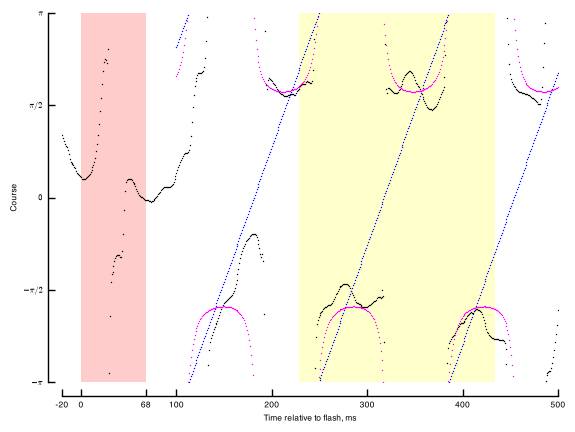

In [20]:
fig = plt.figure()
ax = fig.add_subplot(111)

uap.plot_model_fit(course, best_unifying_algo_fit, 
                   flash_frame_start=20,
                   flash_frame_end=88,
                   clean_spines=True,
                   ax=ax,
                   course_marker_size=2,
                   linear_marker_size=2,
                   affine_marker_size=2,
                  )

In [21]:
ax = layout.axes[('laminar_example', 'course')]
uap.plot_model_fit(course, best_unifying_algo_fit, 
                   flash_frame_start=20,
                   flash_frame_end=88,
                   clean_spines=True,
                   ax=ax,
                   course_marker_size=2,
                   linear_marker_size=2,
                   affine_marker_size=2,
                  )

In [22]:
print('median slope: ', unifying_algo_fit['slope'].abs().median())
print('median axis ratio: ', unifying_algo_fit['axis_ratio'].abs().median())
print('weighted median: ', uaa.get_weighted_value(unifying_algo_fit, col='axis_ratio', use='rmse_affine'))

median slope:  0.04642310939711494
median axis ratio:  0.060076340826011015
weighted median:  0.08488008289331693


In [23]:
clean_labels(ax, show_labels)

In [24]:
# Course vs time panels are left as vector graphics (no rasterization)

layout.append_figure_to_layer(layout.figures['laminar_example'], 'laminar_example', cleartarget=True)
layout.write_svg(FIGURE_NAME)

# With real still air data

In [25]:
show_labels = True

In [26]:
layout = fifi.svg_to_axes.FigureLayout(FIGURE_NAME, autogenlayers=True, make_mplfigures=True, hide_layers=[], dpi=600)
plt.close('all')

In [27]:
braid_df_fname =  '../../../../Data/Experimental_Fly_Data/flies_stillair_c1xwt_preprocessed_optotrigger_trimmed.hdf'
df_still = pd.read_hdf(braid_df_fname)

In [28]:
# get a single trajectory
braid_df = df_still[df_still.intensity==100]
obj_id_key = 'obj_id_unique_event'
# obj_id = braid_df[obj_id_key].unique()[36] << 36 is a good demo, 29 & 35 is a good one that switches direction of circling
# obj_id = braid_df[obj_id_key].unique()[36] # '20220817_173045_4200_104' is a tricky one
trajec = braid_df[braid_df[obj_id_key]=='20220815_162329_1835_55']
trajec = trajec.dropna()

In [29]:
if 0:
    braid_analysis_plots.plot_arrowhead_trajectory(trajec.x.values, trajec.y.values)
else:
    ax = layout.axes[('stillair_example', 'trajec')]

    if 0:
        x_pos = trajec.x.values
        y_pos = trajec.y.values
        braid_analysis_plots.plot_arrowhead_trajectory(x_pos[0:20], y_pos[0:20], color='gray', linewidth=1, ax=ax, arrow_length=0)
        braid_analysis_plots.plot_arrowhead_trajectory(x_pos[20:87], y_pos[20:87], color='red', linewidth=1, ax=ax, arrow_length=0)
        braid_analysis_plots.plot_arrowhead_trajectory(x_pos[87:], y_pos[87:], color='black', linewidth=1, ax=ax, arrow_length=0.03)
        
        
        ax.set_xlim(-0.25, 0.35)
        ax.set_ylim(-0.15, 0.15)
        ax.set_aspect('equal')
        
    else:
        x_pos = trajec.x.values
        y_pos = trajec.y.values
        cmap, color_feature = make_lights_time_cmap(trajec.lights_on, trajec.time_relative_to_flash)
        plot_arrowhead_trajectory_scaled(x_pos, y_pos, color='black', arrow_length=0.1, arrow_angle=30,
                                         ax=ax, linewidth=0.75, scale_bar=True, units='m', fontsize=6, 
                                         padding=0.05,
                                         flow_direction=None, flow_column_width=0,
                                         cmap=cmap,
                                         color_feature=color_feature,
                                         color_feature_min=0,   # pin the norm so sentinel values map correctly
                                         color_feature_max=2,
                                         rasterized=True)
    
    fifi.mpl_functions.adjust_spines(ax, [])

In [30]:
course = trajec.course_smoothish.values
abs_min_ix = 120 # 1 second after the flash start; roughly 300 ms after flash end. Adjust based on your data.
abs_max_ix = 500 # 5 seconds after the flash start. 
min_ix_range = 190 # Use a ~2 sec window for fit
max_ix_range = 210 # Use a ~2 sec window for fit

In [31]:
unifying_algo_fit = get_unifying_algo_fit(course, trajec[obj_id_key].iloc[0], 'stillair_data_flash', seed=2)

In [32]:
# Sort 
sorted_fit = unifying_algo_fit.sort_values('rmse_affine')
best_ix = sorted_fit.index[0]
best_unifying_algo_fit = unifying_algo_fit.iloc[best_ix]

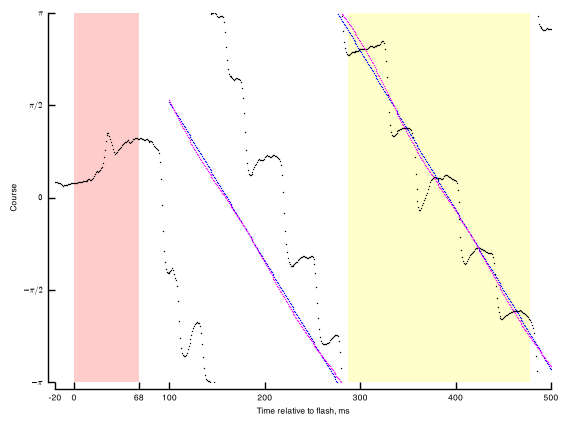

In [33]:
fig = plt.figure()
ax = fig.add_subplot(111)

uap.plot_model_fit(course, best_unifying_algo_fit, 
                   flash_frame_start=20,
                   flash_frame_end=88,
                   clean_spines=True,
                   ax=ax,
                   course_marker_size=2,
                   linear_marker_size=2,
                   affine_marker_size=2,
                  )

In [34]:
sorted_fit.keys()

Index(['min_ix', 'max_ix', 'abs_min_ix', 'abs_max_ix', 'min_ix_range',
       'max_ix_range', 'slope', 'intercept', 'rotation', 'major_axis',
       'minor_axis', 'AM_0_0', 'AM_0_1', 'AM_1_0', 'AM_1_1', 'tx', 'ty', 'rho',
       'mean_residuals', 'axis_ratio', 'rmse_affine', 'shift_ix', 'iteration',
       'obj_id_unique_event', 'timestep_sec'],
      dtype='object')

In [35]:
ax = layout.axes[('stillair_example', 'course')]
uap.plot_model_fit(course, best_unifying_algo_fit, 
                   flash_frame_start=20,
                   flash_frame_end=88,
                   clean_spines=True,
                   ax=ax,
                   course_marker_size=2,
                   linear_marker_size=2,
                   affine_marker_size=2,
                  )

In [36]:
print('median slope: ', unifying_algo_fit['slope'].abs().median())
print('median axis ratio: ', unifying_algo_fit['axis_ratio'].abs().median())
print('weighted median: ', uaa.get_weighted_value(unifying_algo_fit, col='axis_ratio', use='rmse_affine'))

median slope:  0.029861896994411576
median axis ratio:  0.869621893136949
weighted median:  0.8668788076349436


In [37]:
clean_labels(ax, show_labels)

In [38]:
# Course vs time panels are left as vector graphics (no rasterization)

layout.append_figure_to_layer(layout.figures['stillair_example'], 'stillair_example', cleartarget=True)
layout.write_svg(FIGURE_NAME)

# With real unsteady data

In [39]:
show_labels = False

In [40]:
layout = fifi.svg_to_axes.FigureLayout(FIGURE_NAME, autogenlayers=True, make_mplfigures=True, hide_layers=[], dpi=600)
plt.close('all')

In [41]:
braid_df_fname =  '../../../../Data/Experimental_Fly_Data/flies_splitflow_topon_c1xwt_preprocessed_optotrigger_trimmed.hdf'
df_unsteady = pd.read_hdf(braid_df_fname)

In [42]:
# get a single trajectory
braid_df = df_unsteady[df_unsteady.intensity>0]
obj_id_key = 'obj_id_unique_event'
obj_id = braid_df[obj_id_key].unique()[2] # 0
trajec = braid_df[braid_df[obj_id_key]=='20240110_164820_3734_82']
trajec = trajec.dropna()

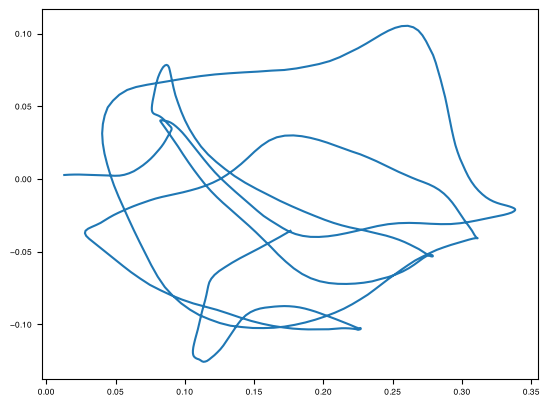

In [43]:
plt.plot(trajec.x, trajec.y)

In [44]:
if 0:
    braid_analysis_plots.plot_arrowhead_trajectory(trajec.x.values, trajec.y.values)
else:
    ax = layout.axes[('unsteady_example', 'trajec')]

    if 0:
        x_pos = trajec.x.values
        y_pos = trajec.y.values
        braid_analysis_plots.plot_arrowhead_trajectory(x_pos[0:20], y_pos[0:20], color='gray', linewidth=1, ax=ax, arrow_length=0)
        braid_analysis_plots.plot_arrowhead_trajectory(x_pos[20:87], y_pos[20:87], color='red', linewidth=1, ax=ax, arrow_length=0)
        braid_analysis_plots.plot_arrowhead_trajectory(x_pos[87:], y_pos[87:], color='black', linewidth=1, ax=ax, arrow_length=0.03)
        
        
        ax.set_xlim(-0.4, 0.05)
        ax.set_ylim(-0.1, 0.2)
        ax.set_aspect('equal')
    else:
        x_pos = trajec.x.values
        y_pos = trajec.y.values
        cmap, color_feature = make_lights_time_cmap(trajec.lights_on, trajec.time_relative_to_flash)
        plot_arrowhead_trajectory_scaled(x_pos, y_pos, color='black', arrow_length=0.1, arrow_angle=30,
                                         ax=ax, linewidth=0.75, scale_bar=True, units='m', fontsize=6, 
                                         padding=0.05,
                                         flow_direction=None, flow_column_width=0,
                                         cmap=cmap,
                                         color_feature=color_feature,
                                         color_feature_min=0,   # pin the norm so sentinel values map correctly
                                         color_feature_max=2,
                                         rasterized=True)
        
    fifi.mpl_functions.adjust_spines(ax, [])

In [45]:
course = trajec.course_smoothish.values
abs_min_ix = 120 # 1 second after the flash start; roughly 300 ms after flash end. Adjust based on your data.
abs_max_ix = 500 # 5 seconds after the flash start. 
min_ix_range = 190 # Use a ~2 sec window for fit
max_ix_range = 210 # Use a ~2 sec window for fit

In [46]:
unifying_algo_fit = get_unifying_algo_fit(course, trajec[obj_id_key].iloc[0], 'unsteady_top_on_data_flash', seed=3)

In [47]:
# Sort 
sorted_fit = unifying_algo_fit.sort_values('rmse_affine')
best_ix = sorted_fit.index[0]
best_unifying_algo_fit = unifying_algo_fit.iloc[best_ix]

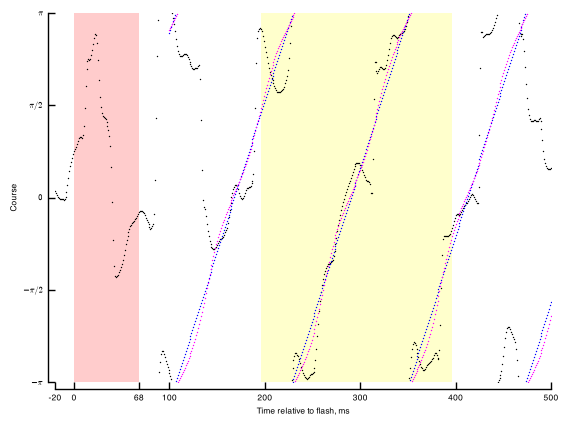

In [48]:
fig = plt.figure()
ax = fig.add_subplot(111)

uap.plot_model_fit(course, best_unifying_algo_fit, 
                   flash_frame_start=20,
                   flash_frame_end=88,
                   clean_spines=True,
                   ax=ax,
                   course_marker_size=2,
                   linear_marker_size=2,
                   affine_marker_size=2,
                  )

In [49]:
if len(unifying_algo_fit):
    ax = layout.axes[('unsteady_example', 'course')]
    uap.plot_model_fit(course, best_unifying_algo_fit, 
                       flash_frame_start=20,
                       flash_frame_end=88,
                       clean_spines=True,
                       ax=ax,
                       course_marker_size=2,
                       linear_marker_size=2,
                       affine_marker_size=2,
                      )

In [50]:
if len(unifying_algo_fit):
    print('median slope: ', unifying_algo_fit['slope'].abs().median())
    print('median axis ratio: ', unifying_algo_fit['axis_ratio'].abs().median())
    print('weighted median: ', uaa.get_weighted_value(unifying_algo_fit, col='axis_ratio', use='rmse_affine'))

median slope:  0.054155370155902285
median axis ratio:  0.5618335225127866
weighted median:  0.5842810563219138


In [51]:
if len(unifying_algo_fit):
    clean_labels(ax, show_labels)

In [52]:
if len(unifying_algo_fit):
    # Course vs time panels are left as vector graphics (no rasterization)

    layout.append_figure_to_layer(layout.figures['unsteady_example'], 'unsteady_example', cleartarget=True)
    layout.write_svg(FIGURE_NAME)

# With real low wind data

In [53]:
show_labels = False

In [54]:
layout = fifi.svg_to_axes.FigureLayout(FIGURE_NAME, autogenlayers=True, make_mplfigures=True, hide_layers=[], dpi=600)
plt.close('all')

In [55]:
braid_df_fname =  '../../../../Data/Experimental_Fly_Data/flies_varwind_C1WT_combined_optotrigger_fancontrol_trimmed.parquet'
df_low = pd.read_parquet(braid_df_fname)

In [56]:
# get a single trajectory
braid_df = df_low[df_low.intensity>0]

obj_id_key = 'obj_id_unique_event'
trajec = braid_df[braid_df[obj_id_key]=='20260406_185025_103927_683'] # from 23speed set: 20260407_170410_5567_174 from 28: 20260406_185025_103927_683
trajec = trajec.dropna()

In [57]:
if 0:
    braid_analysis_plots.plot_arrowhead_trajectory(trajec.x.values, trajec.y.values)
else:
    ax = layout.axes[('low_example', 'trajec')]

    if 0:
        x_pos = trajec.x.values
        y_pos = trajec.y.values
        braid_analysis_plots.plot_arrowhead_trajectory(x_pos[0:20], y_pos[0:20], color='gray', linewidth=1, ax=ax, arrow_length=0)
        braid_analysis_plots.plot_arrowhead_trajectory(x_pos[20:70], y_pos[20:87], color='red', linewidth=1, ax=ax, arrow_length=0)
        braid_analysis_plots.plot_arrowhead_trajectory(x_pos[70:], y_pos[70:], color='black', linewidth=1, ax=ax, arrow_length=0.03)
        
        
        ax.set_xlim(-0.4, 0.05)
        ax.set_ylim(-0.1, 0.2)
        ax.set_aspect('equal')
    else:
        x_pos = trajec.x.values
        y_pos = trajec.y.values
        cmap, color_feature = make_lights_time_cmap(trajec.lights_on, trajec.time_relative_to_flash)
        plot_arrowhead_trajectory_scaled(x_pos, y_pos, color='black', arrow_length=0.1, arrow_angle=30,
                                         ax=ax, linewidth=0.75, scale_bar=True, units='m', fontsize=6, 
                                         padding=0.05,
                                         flow_direction=None, flow_column_width=0,
                                         cmap=cmap,
                                         color_feature=color_feature,
                                         color_feature_min=0,   # pin the norm so sentinel values map correctly
                                         color_feature_max=2,
                                         rasterized=True)
        
    fifi.mpl_functions.adjust_spines(ax, [])

In [58]:
course = trajec.course_smoothish.values
abs_min_ix = 120 # 1 second after the flash start; roughly 300 ms after flash end. Adjust based on your data.
abs_max_ix = 500 # 5 seconds after the flash start. 
min_ix_range = 190 # Use a ~2 sec window for fit
max_ix_range = 210 # Use a ~2 sec window for fit

In [59]:
unifying_algo_fit = get_unifying_algo_fit(course, trajec[obj_id_key].iloc[0], 'varwind_N700_flash_28.0', seed=4)

In [60]:
# Sort 
sorted_fit = unifying_algo_fit.sort_values('rmse_affine')
best_ix = sorted_fit.index[0]
best_unifying_algo_fit = unifying_algo_fit.iloc[best_ix]

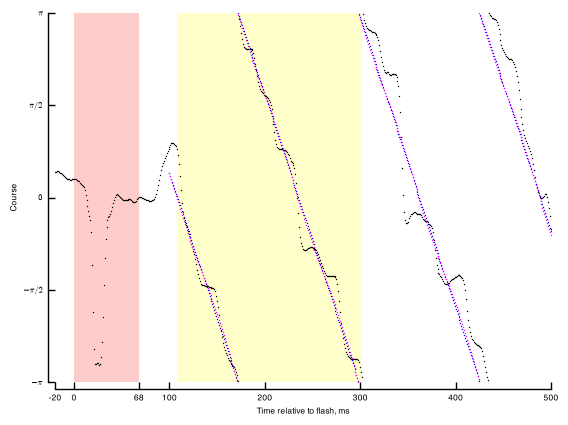

In [61]:
fig = plt.figure()
ax = fig.add_subplot(111)

uap.plot_model_fit(course, best_unifying_algo_fit, 
                   flash_frame_start=20,
                   flash_frame_end=88,
                   clean_spines=True,
                   ax=ax,
                   course_marker_size=2,
                   linear_marker_size=2,
                   affine_marker_size=2,
                  )

In [62]:
ax = layout.axes[('low_example', 'course')]
uap.plot_model_fit(course, best_unifying_algo_fit, 
                   flash_frame_start=20,
                   flash_frame_end=70,
                   clean_spines=True,
                   ax=ax,
                   course_marker_size=2,
                   linear_marker_size=2,
                   affine_marker_size=2,
                  )

In [63]:
print('median slope: ', unifying_algo_fit['slope'].abs().median())
print('median axis ratio: ', unifying_algo_fit['axis_ratio'].abs().median())
print('weighted median: ', uaa.get_weighted_value(unifying_algo_fit, col='axis_ratio', use='rmse_affine'))

median slope:  0.04868659135347188
median axis ratio:  0.7185407685076892
weighted median:  0.7520739776464322


In [64]:
clean_labels(ax, show_labels)

In [65]:
# Course vs time panels are left as vector graphics (no rasterization)

layout.append_figure_to_layer(layout.figures['low_example'], 'low_example', cleartarget=True)
layout.write_svg(FIGURE_NAME)

# Restore font glyphs shared with other panels

In [66]:
# Redrawing a layer deletes the font glyphs defined inside it, even when other panels (e.g. H and I)
# still use them. Copy any such glyphs back from the figure as it was before this notebook ran.
import re

svg = open(FIGURE_NAME).read()
original = ORIGINAL_SVG
missing = set(re.findall(r'href="#([^"]+)"', svg)) - set(re.findall(r'\bid="([^"]+)"', svg))
glyphs = [g.group(0) for m in sorted(missing)
          if (g := re.search(rf'<path id="{re.escape(m)}"[^>]*/>', original))]
if glyphs:
    head, _, tail = svg.rpartition('</svg>')
    svg = head + '<defs>\n' + '\n'.join(glyphs) + '\n</defs>\n</svg>' + tail
    open(FIGURE_NAME, 'w').write(svg)
print(f'restored {len(glyphs)} of {len(missing)} missing glyphs')


restored 0 of 0 missing glyphs
